# Poisson Pressure Solver

Let $(x,y,z)\in]x_{\text{min}}, x_{\text{max}}[\times]y_{\text{min}}, y_{\text{max}}[\times]z_{\text{min}}, z_{\text{max}}]=]0, 2\pi[^3=\Omega$, 
then the Poisson's problem is defined as
\begin{equation}
    \begin{split}
        \nabla^2p(x,y,z) &= \left(\dfrac{\partial^2}{\partial x^2} + \dfrac{\partial^2}{\partial y^2} + \dfrac{\partial^2}{\partial z^2}\right)p(x,y,z) 
            = f(x,y,z) \quad \text{in} ~ \Omega,\\
        \frac{\partial p}{\partial z} &=0, \quad \text{on} ~ z=z_{\text{min}}, \\
        p &= 0, \quad \text{on} ~ z=z_{\text{max}},
    \end{split}
\end{equation}

with periodic boundary conditions in $x$ and $y$ directions, and

\begin{equation}
    f(x,y,z) = \frac{1}{\pi^3}
        \left[
            \left(z^3-2\pi z^2\right)
            \left(
            \dfrac{2}{s_x}\left(1-\dfrac{2}{s_x}(x-x_0)^2\right) + 
            \dfrac{2}{s_y}\left(1-\dfrac{2}{s_y}(y-y_0)^2\right)
            \right) 
            + g(z)
        \right]
        G(x,y,z),
\end{equation}

with

\begin{equation*}
    G(x,y,z)=\exp\left(-\left(\frac{(x - x_0)^2}{s_x} + \frac{(y - y_0)^2}{s_y}+ \frac{(z - z_0)^2}{s_z}\right)\right),
\end{equation*}

and

\begin{equation*}
    g(z) = -\dfrac{4}{s_z}z^5+\left(\dfrac{8\pi  + 8z_0}{s_z^2}\right)z^4 - 
        \left(\dfrac{16\pi z_0 + 4z_0^2-14s_z}{s_z^2}\right)z^3 + \\
        \left(\dfrac{8\pi z_0^2 - 12s_zz_0 - 20\pi s_z}{s_z^2}\right)z^2 + \left(\dfrac{16\pi z_0 - 6s_z}{s_z}\right)z + 4\pi
\end{equation*}

The solution of this problem is
\begin{equation}
    p(x,y,z) = \frac{1}{\pi^3}(2\pi z^2-z^3)\,G(x,y,z).
\end{equation}

We use $x_0=y_0=z_0=\pi$, and $s_x=s_y=s_z=.5$.

In [1]:
import time as time
from fftfd import *

In [2]:
x0 = y0 = z0 = np.pi 
sx = sy = sz = .5
z_min, z_max = 0, 2 * np.pi
k = 2

In [3]:
# Functions
G = lambda x, y, z: np.exp(-((x - x0) ** 2 / sx + (y - y0) ** 2 / sy + (z - z0) ** 2 / sz))
g = lambda z: -4 * z ** 5 / sz ** 2 + (8 * np.pi + 8 * z0) * z ** 4 / sz ** 2 - (16 * np.pi * z0 + 4 * z0 ** 2 - 14 * sz) * z ** 3 / sz ** 2 + \
    (8 * np.pi * z0 ** 2 - 12 * sz * z0 - 20 * np.pi * sz) * z ** 2 / sz ** 2 + (16 * np.pi * z0 - 6 * sz) * z / sz  + 4 * np.pi
p = lambda x, y, z: (2 * np.pi * z ** 2 - z ** 3) * G(x, y, z) / np.pi ** 3
f = lambda x, y, z: ((z ** 3 - 2 * np.pi * z ** 2) * (2 * (1 - 2 * (x - x0) ** 2 / sx) / sx + 2 * (1 - 2 * (y - y0) ** 2 / sy) / sy) + g(z)) * G(x, y, z) / np.pi ** 3
pz = lambda x, y, z: (2 * z ** 4 / sz - (4 * np.pi + 2 * z0) * z ** 3 / sz + (4 * np.pi * z0 - 3 * sz) * z ** 2 / sz + 4 * np.pi * z) * G(x, y, z) / np.pi ** 3
log_abs = lambda p, pa: np.log(np.abs(p - pa) + 1e-16)
r = lambda z: (z_max - z_min) * (np.exp(k * (z - z_min) / (z_max - z_min)) - 1) / (np.exp(k) - 1) + z_min
#r = lambda z: z.shape[0] ** 2 / (2 * (z.shape[0] ** 2 -1) * np.pi) * z ** 2 + (z[1] - z[0])

In [4]:
def experiment(Nx, Ny, Nz, uniform=True):
    x = np.linspace(0, 2 * np.pi, Nx)
    y = np.linspace(0, 2 * np.pi, Ny)
    z = np.linspace(0, 2 * np.pi, Nz)
    if not uniform:
        z = r(z)
    X, Y, Z = np.meshgrid(x, y, z, indexing='ij')
    P = p(X, Y, Z)
    F = f(X, Y, Z)
    return x, y, z, P, F

In [5]:
N = 32
x, y, z_nu, P_nu, F_nu = experiment(N, N, N, False)
x, y, z, P, F = experiment(N, N, N)
P_a_nu = fftfd_non_uniform_z(F_nu, x, y, z_nu)
P_a = fftfd(F, x, y, z)

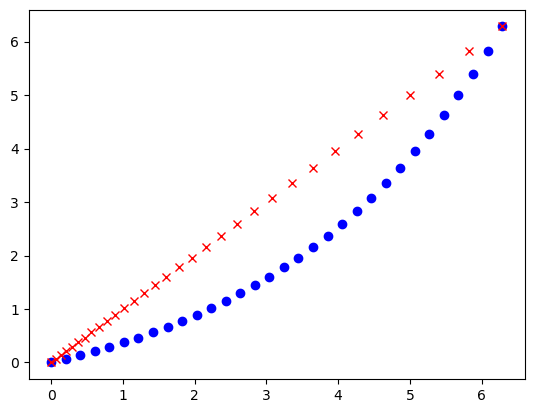

In [6]:
plt.plot(z, z_nu, 'bo')
plt.plot(z_nu, z_nu, 'rx')
# plt.plot(z[:-1], np.diff(z_nu), 'gx')
# plt.plot(z[:-1], np.diff(z), 'bo')
plt.show()

In [7]:
P_nu.min(), P_nu.max()

(-2.353585917619679e-24, 0.9348210079359416)

## Uniform grid

The method previously developed

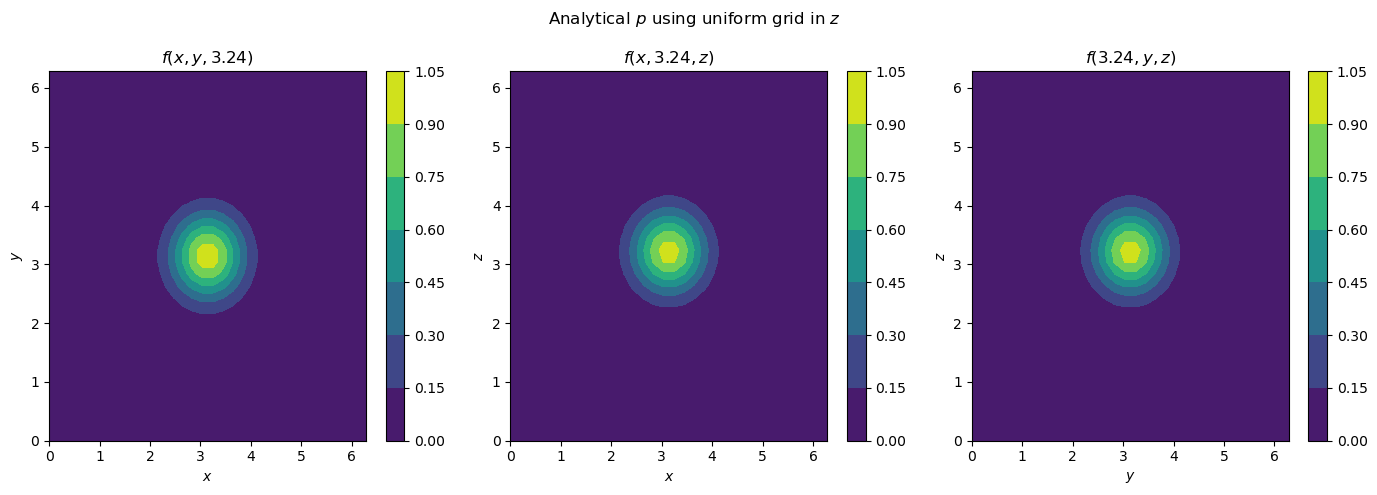

In [8]:
plot(x, y, z, P, r"Analytical $p$ using uniform grid in $z$")

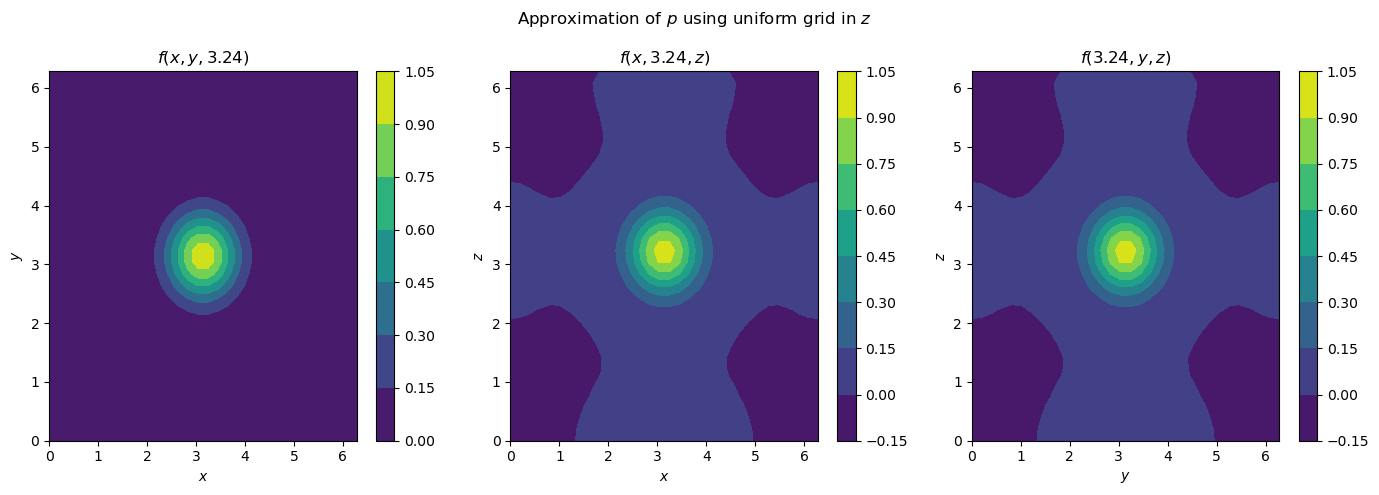

In [9]:
plot(x, y, z, P_a, r"Approximation of $p$ using uniform grid in $z$")

## Non-uniform grid

The proposed method

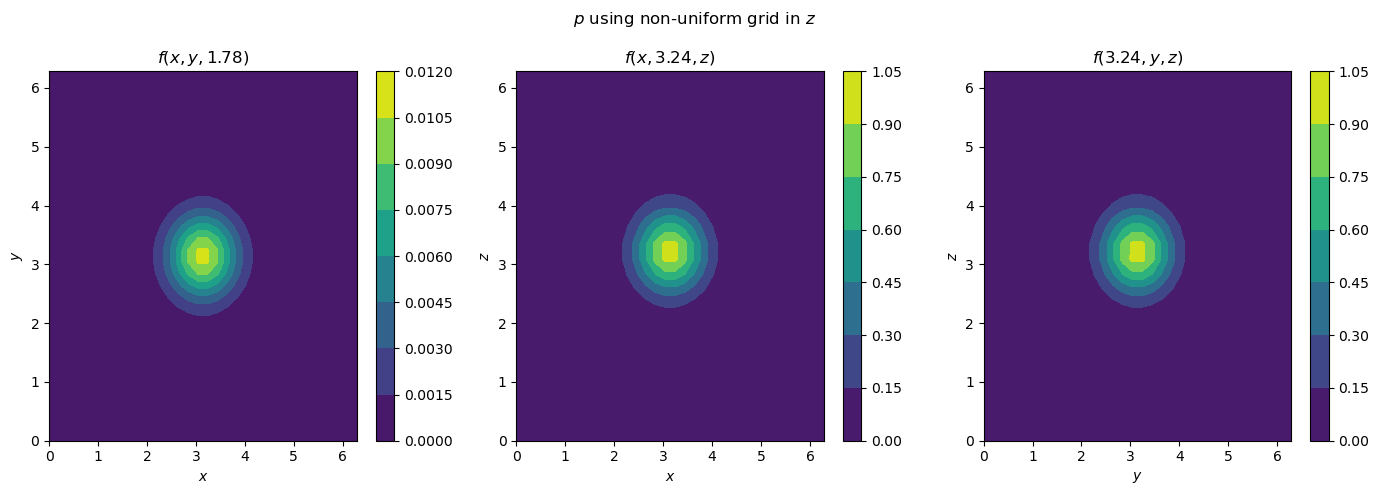

In [10]:
plot(x, y, z_nu, P_nu, r"$p$ using non-uniform grid in $z$")

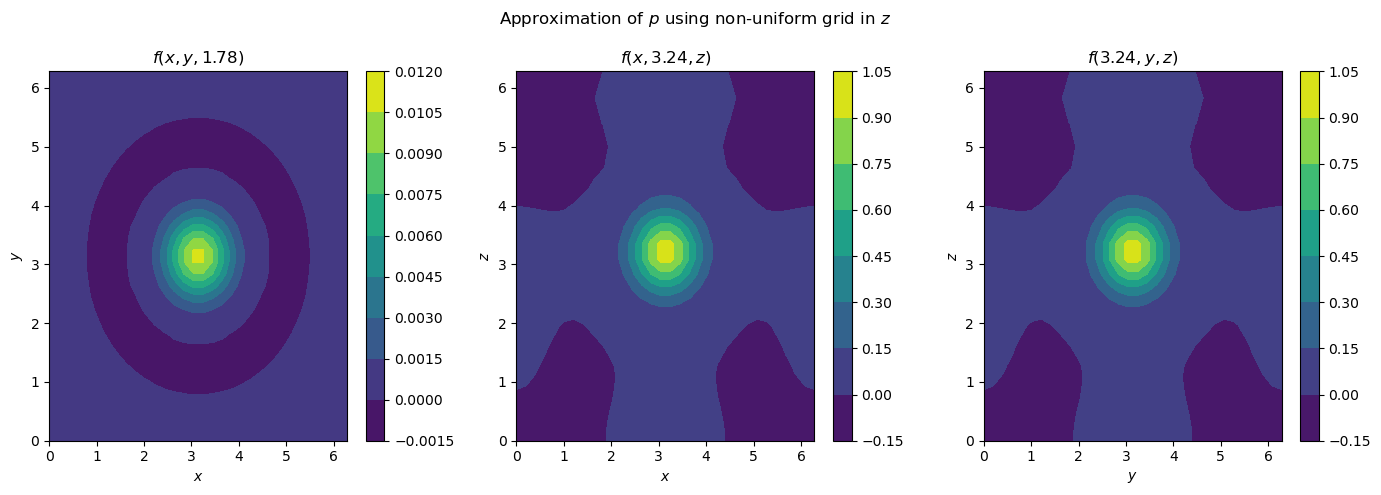

In [11]:
plot(x, y, z_nu, P_a_nu, r"Approximation of $p$ using non-uniform grid in $z$")

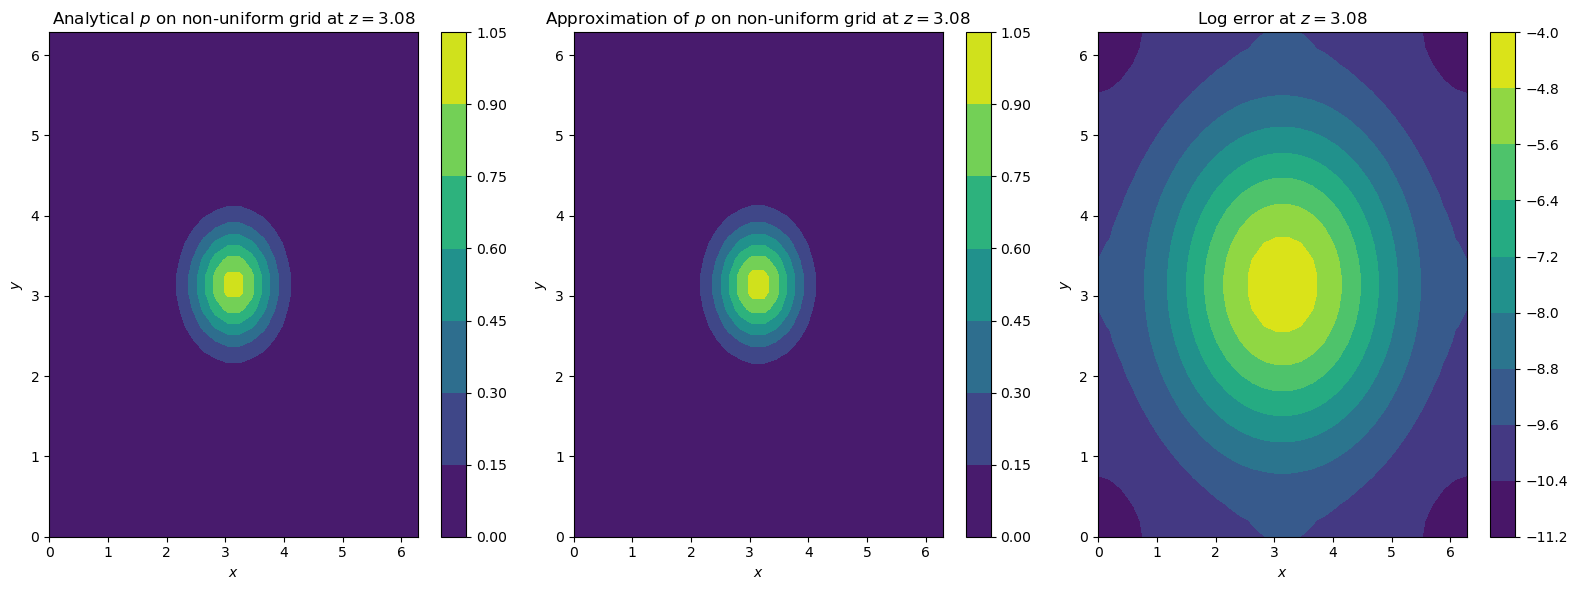

In [12]:
# Find k closest to np.pi
k = np.argmin(np.abs(z_nu - np.pi))
# k = -10
plt.figure(figsize=(16, 6))
plt.subplot(131)
plt.contourf(x, y, P_nu[:, :, k].T)
plt.title("Analytical $p$ on non-uniform grid at $z = {}$".format(round(z_nu[k], 2)))
plt.colorbar()
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.subplot(132)
plt.contourf(x, y, P_a_nu[:, :, k].T)
plt.title("Approximation of $p$ on non-uniform grid at $z = {}$".format(round(z_nu[k], 2)))
plt.colorbar()
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.subplot(133)
plt.contourf(x, y, log_abs(P_nu[:, :, k], P_a_nu[:, :, k]).T)
plt.title("Log error at $z = {}$".format(round(z_nu[k], 2)))
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.colorbar()
plt.tight_layout()
plt.show()

In [13]:
np.linalg.norm(P_nu - P_a_nu) #/ np.linalg.norm(P_nu)

0.14518855203183562

In [14]:
np.linalg.norm(P - P_a)

0.08929184737461707

In [15]:
errors = np.abs(P_nu - P_a_nu)

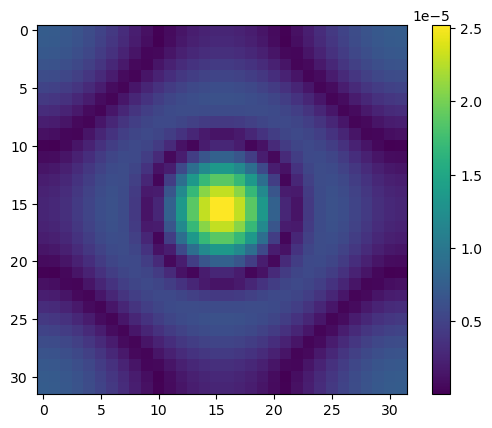

In [16]:
plt.imshow(errors[:, :, 0].T)
plt.colorbar()
plt.show()

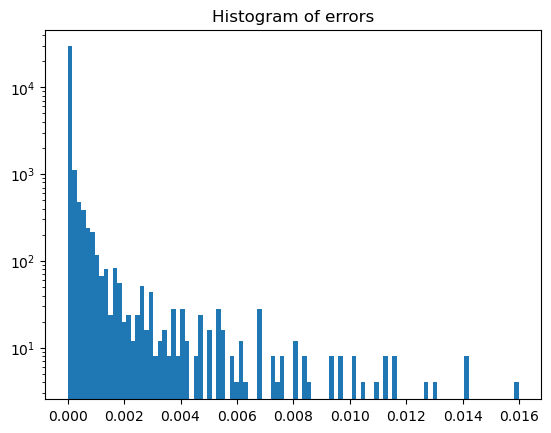

In [17]:
plt.hist(errors.flatten(), bins=100)
plt.title("Histogram of errors")
plt.yscale('log')
plt.show()

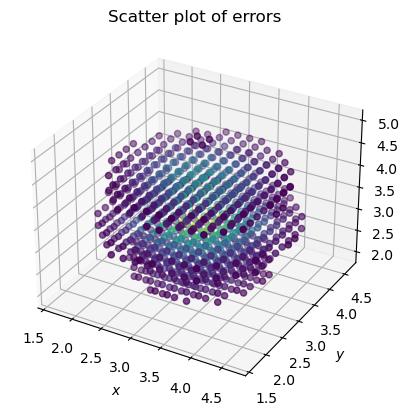

In [18]:
# Scatter 3D of the errors
X, Y, Z = np.meshgrid(x, y, z_nu, indexing='ij')
mask = np.abs(P_nu - P_a_nu) > 1e-3
X = X[mask]
Y = Y[mask]
Z = Z[mask]
errors = np.abs(P_nu - P_a_nu)[mask]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X.flatten(), Y.flatten(), Z.flatten(), c=errors.flatten(), cmap='viridis')
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
plt.title("Scatter plot of errors")
plt.show()

In [42]:
Ns = np.array([32, 64, 128, 256])
errors_u = np.zeros(len(Ns))
errors_nu = np.zeros(len(Ns))
times = np.zeros(len(Ns))
dzs_u = np.zeros(len(Ns))
dzs_nu = np.zeros(len(Ns))
N_exp = 5
for i in range(len(Ns)):
    N = Ns[i]
    print("Computing for N =", N)
    x_u, y_u, z_u, P_u, F_u = experiment(N, N, N, True)
    x_nu, y_nu, z_nu, P_nu, F_nu = experiment(N, N, N, False)
    start = time.time()
    for e in range(N_exp):
        P_a_nu_e = fftfd_non_uniform_z(F_nu, x_nu, y_nu, z_nu)
    end = time.time()
    P_a_u_e = fftfd(F_u, x_u, y_u, z_u)
    dzs_u[i] = z_u[1] - z_u[0] 
    dzs_nu[i] = np.max(z_nu[1:] - z_nu[:-1])   
    errors_u[i] = np.linalg.norm(P_a_u_e.flatten() - P_u.flatten()) / np.linalg.norm(P_a_nu_e.flatten())
    errors_nu[i] = np.linalg.norm(P_a_nu_e.flatten() - P_nu.flatten()) / np.linalg.norm(P_a_nu_e.flatten())
    # errors_u[i] = np.linalg.norm(P_a_u_e.flatten() - P_u.flatten(), np.inf) 
    # errors_nu[i] = np.linalg.norm(P_a_nu_e.flatten() - P_nu.flatten(), np.inf)
    times[i] = (end - start) / N_exp

Computing for N = 32
Computing for N = 64
Computing for N = 128
Computing for N = 256


[]

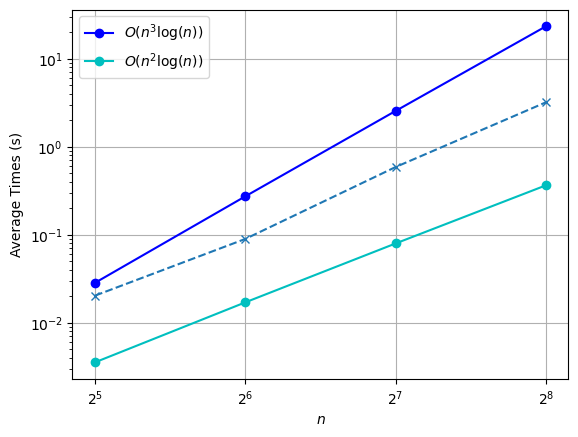

In [43]:
plt.plot(Ns, times, 'x--')
plt.plot(Ns, Ns ** 3 * np.log(Ns) / 4e6, 'b-o', label=r'$O(n^3 \log(n))$')
plt.plot(Ns, Ns ** 2 * np.log(Ns) / 1e6, 'c-o', label=r'$O(n^2 \log(n))$')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$n$')
plt.ylabel('Average Times (s)')
plt.xscale('log', base=2)
plt.legend()
plt.plot()

In [44]:
dzs_nu, errors_nu

(array([3.19309707, 1.85198403, 0.99936848, 0.51935316]),
 array([0.99826598, 0.99136535, 0.07808671, 0.01960967]))

In [45]:
dzs_u

array([0.2026834 , 0.0997331 , 0.0494739 , 0.02463994])

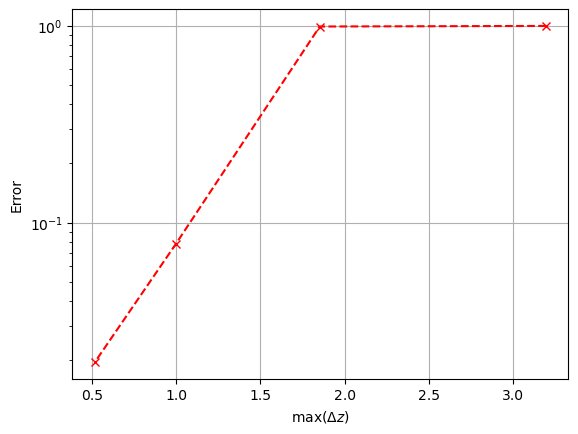

In [48]:
plt.plot(dzs_nu, errors_nu, 'x--r')
# plt.plot(dzs_u, dzs_u ** 2 / 3, 'b-o', label=r'$O(\Delta z^2)$')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$\max(\Delta z)$')
plt.ylabel('Error')
# plt.xscale('log', base=2)
# plt.legend()
plt.show()

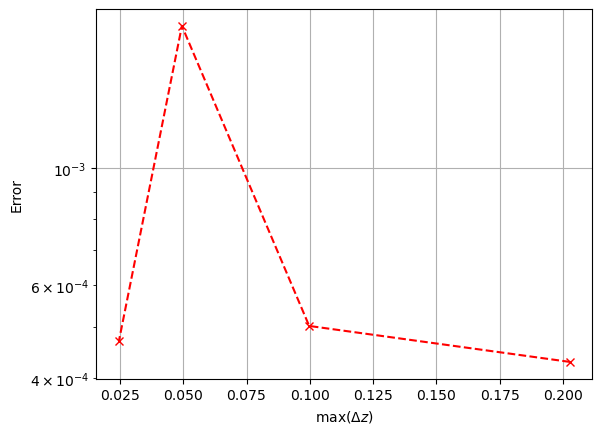

In [49]:
plt.plot(dzs_u, errors_u, 'x--r')
#plt.plot(dzs, dzs ** 2 / 3, 'b-o', label=r'$O(\Delta z^2)$')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$\max(\Delta z)$')
plt.ylabel('Error')
# plt.xscale('log', base=2)
# plt.legend()
plt.show()


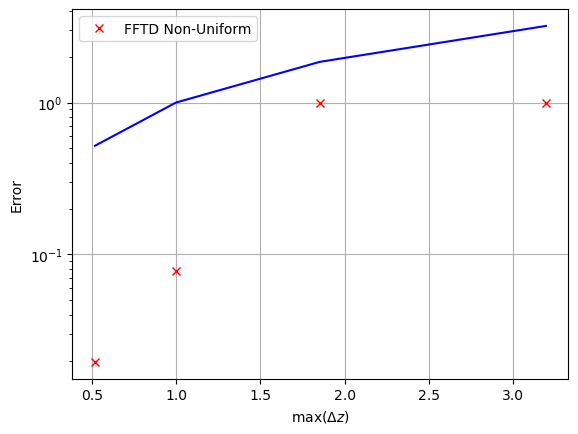

In [54]:
plt.plot(dzs_nu, errors_nu, 'xr', label="FFTD Non-Uniform")
# plt.plot(dzs_u, errors_u, 'ob', label="FFTD Uniform")
#plt.plot(dzs, dzs ** 2 / 3, 'b-o', label=r'$O(\Delta z^2)$')
plt.plot(dzs_nu, dzs_nu, 'b-')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$\max(\Delta z)$')
plt.ylabel('Error')
# plt.xscale('log', base=2)
plt.legend()
plt.show()

In [25]:
np.linalg.norm(errors_u - errors_nu)

1.5271520260196942e-14

For the presentation...

In [26]:
print("$N$ & Time (s)  \\\\")
for i in range(len(Ns)):
    print("%d & $%.2f$ \\\\" % (Ns[i], times[i]))

print("N Time")
for i in range(len(Ns)):
    print("%d  %.6f" % (Ns[i], times[i]))

$N$ & Time (s)  \\
32 & $0.02$ \\
64 & $0.09$ \\
128 & $0.59$ \\
256 & $3.15$ \\
N Time
32  0.018939
64  0.089240
128  0.586332
256  3.145182


In [ ]:
print("$\Delta z$ & Error  \\\\")
for i in range(len(Ns)):
    print("$%.2f$ & $%.8f$ \\\\" % (dzs[i], errors[i]))
print("dz Error")
for i in range(len(Ns)):
    print("%.8f  %.8f" % (dzs[i], errors[i]))

---